In [2]:
%matplotlib inline

import sys
import math
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from natsort import natsorted
from matplotlib.animation import FuncAnimation 
from IPython.display import HTML
from utils import *
from kernels import *

# Jupyter CWD is the notebook's folder (Analysis/), so ".." is the project root
sys.path.insert(0, str(Path().resolve().parent))
# Path() means the current working directory
# resolve() make it absolute but there is no parameter in Path(), so it's actually adundant
# sys.path is a list, python would search this list once it's going to import a module

from Condition_model import samplers, dataset, forecasting, utils
from Condition_model.dataset import SQGDataset, SQGLeadTimeDataset, DATA_PATH, DATA_500, DATA_test


In [3]:

invert_data_path = DATA_PATH / 'invert' / 'invert_steps=100'
test_invert_data_path = DATA_PATH / 'invert' / 'test'

Z, traj, anchor = load_invert(invert_data_path)
Z_test, traj_test, anchor_test = load_invert(test_invert_data_path)
# num of trajectories
N = Z.shape[0]
# initial maximum lead time
L = Z.shape[1]
# lead time but in vector
leads = [l for l in range(L)]
# total dimension
d = math.prod(Z.shape)


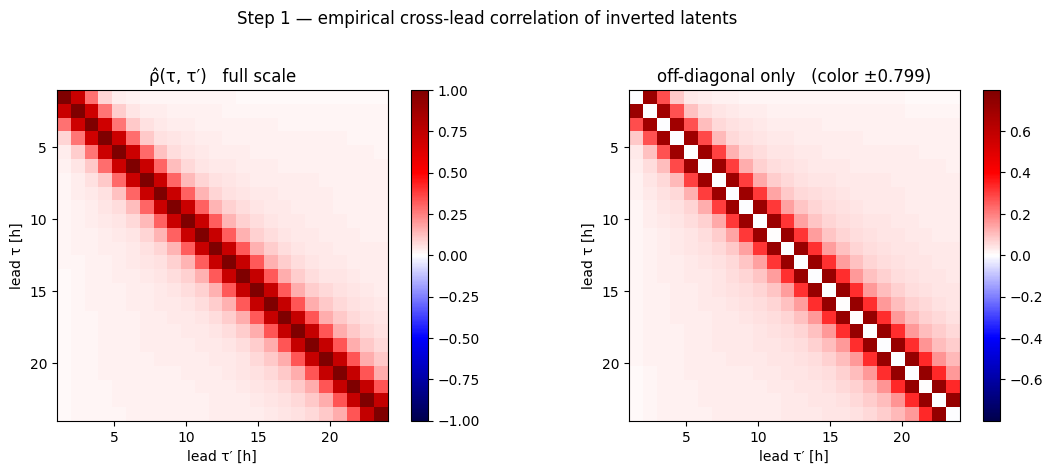

In [4]:
rho, rho_bar, var_l = empirical_correlation(Z) 

off = rho_bar[~np.eye(L, dtype=bool)]
vmax = max(np.abs(off).max() * 1.1, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
im0 = axes[0].imshow(rho_bar, cmap="seismic", vmin=-1, vmax=1, extent=[1, 24, 24, 1])
axes[0].set_title("ρ̂(τ, τ′)   full scale")
im1 = axes[1].imshow(rho_bar - np.eye(L), cmap="seismic", vmin=-vmax, vmax=vmax, extent=[1, 24, 24, 1])
axes[1].set_title(f"off-diagonal only   (color ±{vmax:.3f})")
for ax, im in zip(axes, [im0, im1]):
    ax.set_xlabel("lead τ′ [h]"); ax.set_ylabel("lead τ [h]")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Step 1 — empirical cross-lead correlation of inverted latents", y=1.02)
fig.tight_layout()
plt.show()



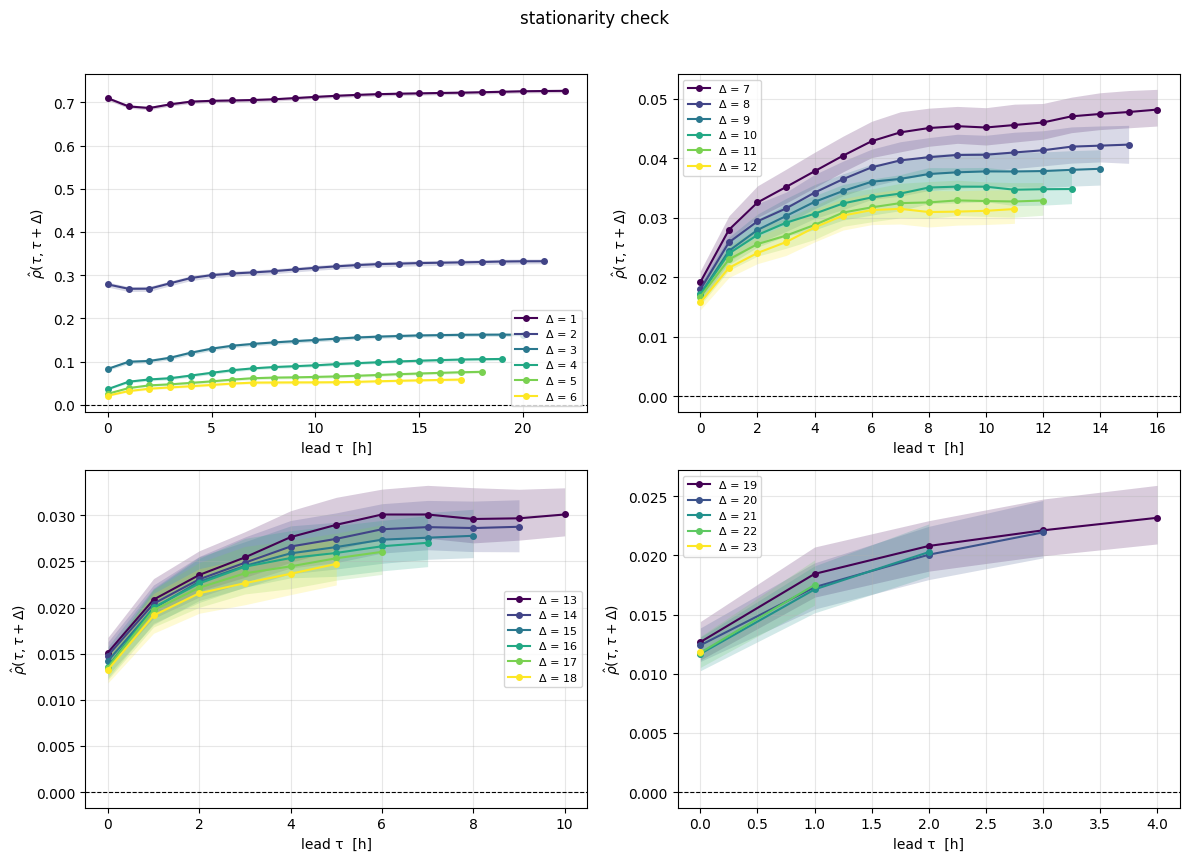

In [5]:

deltas, rho_collap_bar, rhos_collap = collapse_by_lag(rho)
ci_lower, ci_upper = np.percentile(rhos_collap, [2.5, 97.5], axis=1)   # per-window spread, used by Step 2b

rho_boot = bootstrap_rho(Z)   

band = lambda D: np.percentile(np.diagonal(rho_boot, offset=D, axis1=1, axis2=2),
                               [2.5, 97.5], axis=0)             # (2, L-D)
std = lambda D: np.diagonal(rho_boot, offset=D, axis1=1, axis2=2).std(axis=0, ddof=1).mean()

n_plots = 4
deltas_split = np.array_split(deltas, n_plots)

fig, axes = plt.subplots(n_plots // 2, 2, figsize=(12, 8.4))
axes = axes.flatten()  # Flatten to 1D indexing

for plot_idx, plot in enumerate(deltas_split):
    for i, D in enumerate(plot):
        tau, col = leads[:L - D], plt.cm.viridis(i / (len(plot) - 1))
        lo, hi = band(D)
        axes[plot_idx].fill_between(tau, lo, hi, color=col, alpha=0.20, lw=0)
        axes[plot_idx].plot(tau, np.diagonal(rho_bar, offset=D), "o-", ms=4, color=col, label=f"Δ = {D}")
    
    axes[plot_idx].axhline(0, color="k", lw=0.8, ls="--")
    axes[plot_idx].set_xlabel("lead τ  [h]")
    axes[plot_idx].set_ylabel(r"$\hat\rho(\tau, \tau+\Delta)$")
    axes[plot_idx].legend(fontsize=8)
    axes[plot_idx].grid(alpha=0.3)

fig.suptitle("stationarity check", y=1.02)
fig.tight_layout()
plt.show()



/tmp/ipykernel_12195/923812399.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


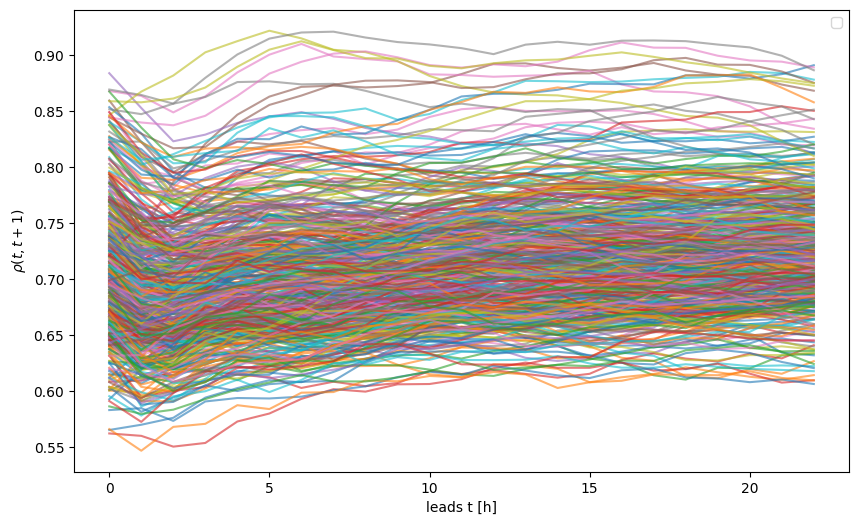

In [6]:
# plot rho_bar(delta = 1) = Cov(eps{t}, eps{t-1})
empirical_rho1 = np.diagonal(rho, offset=1, axis1=1, axis2=2)
empirical_rho1.shape

plt.figure(figsize=(10, 6))

for i in range(N):
    plt.plot(leads[:23], empirical_rho1[i], alpha=0.6)

plt.xlabel("leads t [h]")
plt.ylabel(r"$\rho(t, t+1)$")
plt.legend()
plt.show()
# from this plot, rho(t, t+1) is dependent on x0 and t
# specify this part, if it is dependent on trajectory or x0

/tmp/ipykernel_12195/1429557006.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


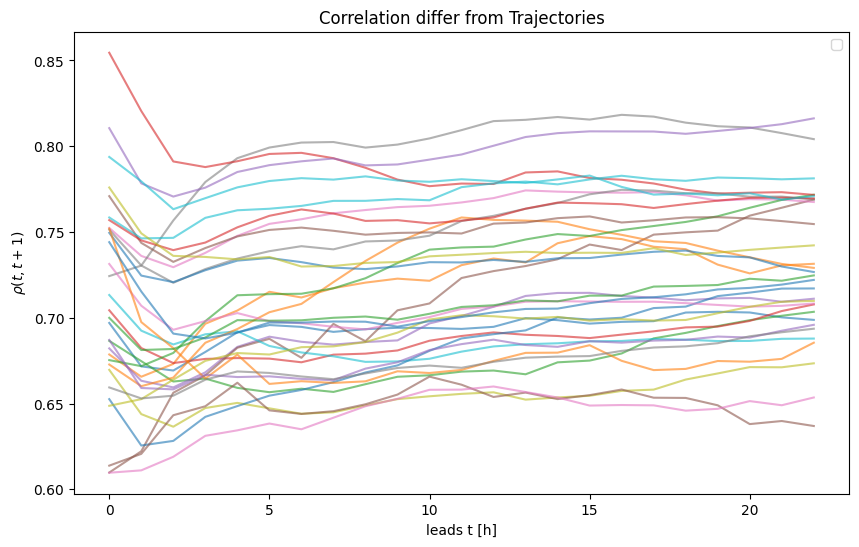

In [ ]:
# QUESTION: is the cov same within a trajectory? 
traj_idx = {}
for idx, t in enumerate(traj):
    if t not in traj_idx:
        traj_idx[t] = []
    traj_idx[t].append(idx)

plt.figure(figsize=(10, 6))
for key in traj_idx:
    if key > 430:
        break
    emp_rho_idx = traj_idx.get(key)
    emp_rho_bar = np.mean([empirical_rho1[i] for i in emp_rho_idx], axis=0)
    plt.plot(leads[:23], emp_rho_bar, alpha=0.6)

plt.xlabel("leads t [h]")
plt.ylabel(r"$\rho(t, t+1)$")
plt.title(f"Correlation differ from Trajectories")
plt.legend()
plt.show()


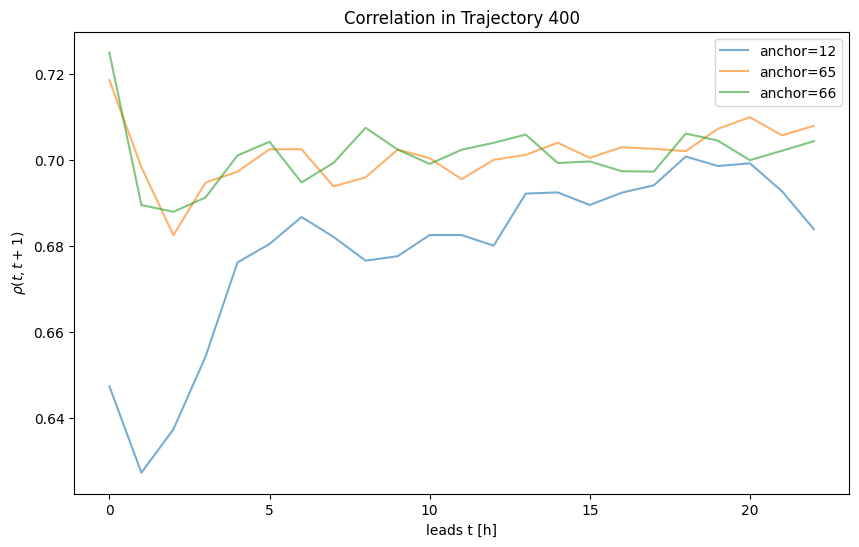

In [36]:


# take trajectory 400 as the example
traj_ex = 400
idx = traj_idx.get(traj_ex)

example_rho = [empirical_rho1[i] for i in idx]

plt.figure(figsize=(10, 6))
for i, example in enumerate(example_rho):
    plt.plot(leads[:23], example, alpha=0.6, label=f"anchor={anchor[idx[i]]}")

plt.xlabel("leads t [h]")
plt.ylabel(r"$\rho(t, t+1)$")
plt.title(f"Correlation in Trajectory {traj_ex}")
plt.legend()
plt.show()

# ok, I guess trajectory doesn't matter
# so if alpha = rho(eps_t, eps_t+1), it must be alpha(t, x0)

$\alpha(x_0, t)$

In [6]:

# really simple visual check
# if they look same 
alphas = alpha(Z)    # (n, L, 1)
alphas = np.squeeze(alphas)
alpha_bar = alphas.mean(axis=0) # (L, 1)


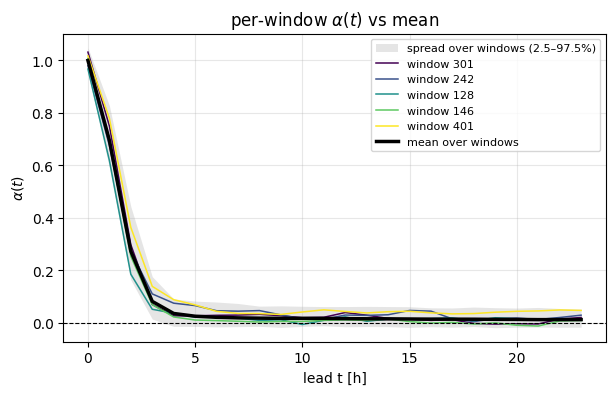

In [7]:
# plot 5 alpha from different windows
# compare to the mean

rng = np.random.default_rng(0)
# pick windows from different trajectories so they're genuinely distinct
pick = rng.choice(alphas.shape[0], size=5, replace=False)

low, high = np.percentile(alphas, [2.5, 97.5], axis=0)   # spread across all windows

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(leads, low, high, color="grey", alpha=0.2, lw=0,
                label="spread over windows (2.5–97.5%)")
for i, n in enumerate(pick):
    ax.plot(leads, alphas[n], "-", lw=1.1, color=plt.cm.viridis(i / 4),
            label=f"window {n} ")
ax.plot(leads, alpha_bar, "k-", lw=2.5, label="mean over windows")
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.set_xlabel("lead t [h]"); ax.set_ylabel(r"$\alpha(t)$")
ax.set_title(r"per-window $\alpha(t)$ vs mean")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()


In [8]:
z0 = Z[:, 0, ...] # z0
zt = Z[:, 1:, ...] # z1:leads
t = leads



matern = minimize(objective, x0=np.log(2.0), args= (matern32, z0, zt), method="L-BFGS-B")
m_ell_hat = np.exp(matern.x)

expon = minimize(objective, x0=np.log(2.0), args= (exponential, z0, zt), method="L-BFGS-B")
e_ell_hat = np.exp(expon.x)

squared = minimize(objective, x0=np.log(2.0), args= (squared_exponential, z0, zt), method="L-BFGS-B")
s_ell_hat = np.exp(squared.x)

stretched = minimize(objective_stretch, x0=np.log([5.0, 1.0]), args= (z0, zt), method="L-BFGS-B")
str_ell_hat, str_p_hat = np.exp(stretched.x)





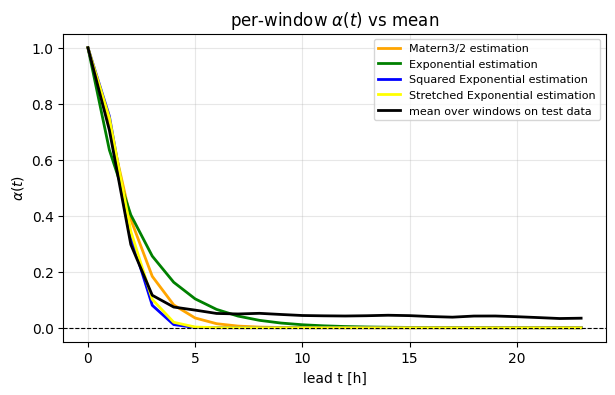

In [9]:
leads = np.array(leads)
estimation = {'matern32' : matern32(leads, m_ell_hat),
              'exponential': exponential(leads, e_ell_hat),
              'squared_exponential': squared_exponential(leads, s_ell_hat),
              'stretched_exponential': stretched_exponential(leads, str_ell_hat, str_p_hat)}

alphas_test_mean = np.squeeze(alpha(Z_test)).mean(axis=0)  # (L, 1)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(leads, estimation.get('matern32'), "-", lw=2, label="Matern3/2 estimation", color='orange')
ax.plot(leads, estimation.get('exponential'), "-", lw=2, label="Exponential estimation", color='green')
ax.plot(leads, estimation.get('squared_exponential'), "-", lw=2, label="Squared Exponential estimation", color='blue')
ax.plot(leads, estimation.get('stretched_exponential'), "-", lw=2, label="Stretched Exponential estimation", color='yellow')

ax.plot(leads, alphas_test_mean,  "k-", lw=2, label="mean over windows on test data")
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.set_xlabel("lead t [h]"); ax.set_ylabel(r"$\alpha(t)$")
ax.set_title(r"per-window $\alpha(t)$ vs mean")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

In [10]:

t = 4
print(RMSE(estimation.get('matern32'), alphas, t))
print(RMSE(estimation.get('exponential'), alphas, t))
print(RMSE(estimation.get('squared_exponential'), alphas, t))
print(RMSE(estimation.get('stretched_exponential'), alphas, t))



0.09346514376204415
0.1242813258689142
0.06583749636900986
0.06955332770275978


In [18]:
# if we want to fit a constant at first
# basically we assume it's stationary
# if our model is AR(1)
# alpha is namely empirical rho(delta=1)
optimal_alpha = rho_collap_bar[0]
# so basically this one
print(optimal_alpha)
print(np.exp(-np.log(10)))


# if our model is not AR(1) but we want to fit the cov(eps0, epst) (alpha)
# with a constant, basically impossible

0.7126076817512512
0.09999999999999998


In [12]:
N = 10
ens = 5
_, leads, C, H, W = Z.shape
latent_shape = (N, ens, leads, C, H, W)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# matern_latent = get_latents(latent_shape, estimation.get('matern32'), device)
# expon_latent = get_latents(latent_shape, estimation.get('exponential'), device)
# squared_expon_latent = get_latents(latent_shape, estimation.get('squared_exponential'), device)
alpha_t = np.diagonal(rho_bar, offset=1)
alpha_t = np.insert(alpha_t, 0, 0)

# the best fitted kernel by learning cov(eps0, epst)
stretched_expon_latent = get_latents(latent_shape, estimation.get('stretched_exponential'), device)
# what I used to forecast at first
ar1_latent = get_latents(latent_shape=latent_shape, alpha=0.5 , device=device, markov=True)
# the same model but the optimal alpha under stationary assumption 
ar1_latent_optimal = get_latents(latent_shape=latent_shape, alpha=optimal_alpha , device=device, markov=True)
#PROBLEM: this one is not fitted but using empirical rho(\delta=1) directly on validataion dataset
# the same model but used the empirical correlation directly without assuming stationarity 
ar1_alphas_latents = get_latents(latent_shape=latent_shape, alpha=alpha_t, device=device, markov=True)



In [15]:
from Condition_model.forecasting import forecast_analysis
from Condition_model.samplers import CondSampler
from Condition_model.train import SAVE_PATH
from utils import temporal_difference, plot_temporal_difference

%load_ext autoreload
%autoreload 2

sampler = CondSampler(device=device, steps=100, model_path=SAVE_PATH)

stretched_preds, truths = forecast_analysis(data_dir=DATA_test, latents=stretched_expon_latent,sampler=sampler, n_traj=N, n_ens=ens)
ar1_preds, _ = forecast_analysis(data_dir=DATA_test, latents=ar1_latent, sampler=sampler, n_traj=N, n_ens=ens)
ar1_opt_preds, _ = forecast_analysis(data_dir=DATA_test, latents=ar1_latent_optimal, sampler=sampler, n_traj=N, n_ens=ens)
ar1_alphas_preds, _ = forecast_analysis(data_dir=DATA_test, latents=ar1_alphas_latents, sampler=sampler, n_traj=N, n_ens=ens)



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


100%|██████████| 10/10 [12:09<00:00, 72.97s/it]


<Axes: xlabel='lag t', ylabel='difference'>

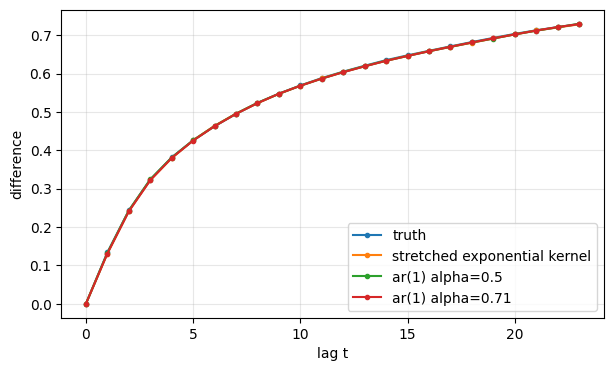

In [16]:
# NOTE: this metric is totally useless, I do this just for showing it's useless
stretched_diff = temporal_difference_with_initial(stretched_preds)
# se_diff = temporal_difference_with_initial(se_preds)
# e_diff = temporal_difference_with_initial(e_preds)
# m_diff = temporal_difference_with_initial(m_preds)
ar1_diff = temporal_difference_with_initial(ar1_preds)
truth_diff = temporal_difference_with_initial(truths)
ar1_opt_diff = temporal_difference_with_initial(ar1_opt_preds)

# diff_dict = {'truth': truth_diff, 
#             'stretched exponential kernel': stretched_diff,
#             'squared exponential kernel': se_diff,
#             'exponential kernel': e_diff,
#             'ar(1) alpha=0.5': ar1_diff,
#             'matern kernel': m_diff}

diff_dict = {'truth': truth_diff, 
            'stretched exponential kernel': stretched_diff,
            'ar(1) alpha=0.5': ar1_diff,
            'ar(1) alpha=0.71': ar1_opt_diff}
plot_temporal_difference(diff_dict)



<Axes: xlabel='lag t', ylabel='difference'>

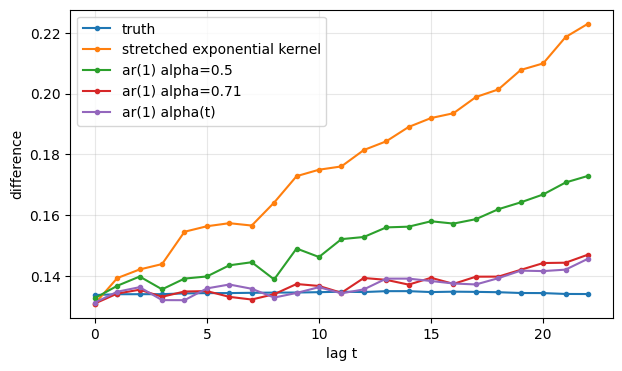

In [17]:
ar1_diff = temporal_difference(ar1_preds)
stretched_diff = temporal_difference(stretched_preds)
truth_diff = temporal_difference(truths)
ar1_opt_diff = temporal_difference(ar1_opt_preds)
ar1_alpha_t_diff = temporal_difference(ar1_alphas_preds)

diff_dict = {'truth': truth_diff, 
            'stretched exponential kernel': stretched_diff,
            'ar(1) alpha=0.5': ar1_diff,
            'ar(1) alpha=0.71': ar1_opt_diff,
            'ar(1) alpha(t)': ar1_alpha_t_diff}

plot_temporal_difference(diff_dict)




In [ ]:
data = {'Truth': truths[0, :, 0, ...], 
        'Stretched Exponential Kernel': stretched_preds[0, 0, :, 0, ...], 
        r'AR1 with $\alpha$=0.5': ar1_preds[0, 0, :, 0, ...],
        r"AR1 with $\alpha=0.71$": ar1_opt_preds[0, 0, :, 0, ...],
        r"AR1 with $\alpha(t)$": ar1_alphas_preds[0, 0, :, 0, ...]}

animation = visualize_results(data, 2)

animation.save('showcase_ar1.gif')


In [22]:
HTML(animation.to_jshtml())